## 다이아몬드 가격 예측
> 다이아몬드 무게(carat)에 따른 적정 가격(price) 추천 모델 생성

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"

random_state=42

### M1 - 데이터 불러오기
> **생각해 볼 질문**
> 
> price 의 평균과 중앙값 중 어느 쪽이 더 큰가요? 그 차이는 가격 분포에 대해 무엇을 말해 주나요?

- 평균이 중앙값보다 더 크다.
- price가 큰 데이터들이 평균을 올렸다. 가격 분포가 오른쪽으로 긴 비대칭이다.

In [200]:
df = sns.load_dataset("diamonds")

print(df.shape) # (53940, 10)
df.head()

df.info()
df.describe()
df.isnull().sum() # 빈 데이터 없음

print("평균:", round(df["price"].mean(), 2)) # 3932.8
print("중앙값:", round(df["price"].median(), 2)) # 2401.0

(53940, 10)
<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB
평균: 3932.8
중앙값: 2401.0


### M2 - 이상치 정리
> **목표**: 말이 안 되는 값을 찾아 근거와 함께 제거하고, 정리된 표 clean 을 만든다.

> **생각해 볼 질문**
> 
> 어떤 행을 왜 지웠나요? 비싼 다이아몬드는 왜 지우면 안 되나요?

- 가로, 세로 높이 중 하나라도 0mm이거나 y나 z가 20mm를 초과하면 비정상적인 데이터로 간주하고 제거한다.
- 비싼 다이아몬드는 이상치가 아니므로 지우지 않는다.

In [201]:
print("가로(x) 0mm:", (df["x"] == 0).sum(), "개") # 8
print("세로(y) 0mm:", (df["y"] == 0).sum(), "개") # 7
print("높이(z) 0mm:", (df["z"] == 0).sum(), "개") # 20

# 이상치 확인
bad_1 = (df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0)
print(f"x/y/z 중 하나라도 0mm: {bad_1.sum()}개") # 20
bad_2 = (df["y"] > 20) | (df["z"] > 20)
print(f"y나 z가 20mm 초과: {bad_2.sum()}개") # 3

df.loc[bad_1]
df.loc[bad_2]

# 이상치 정리
clean = df[~(bad_1 | bad_2)].copy()
print(f"제거 전: {len(df)}행 => {(bad_1 | bad_2).sum()}행 제거 후: {len(clean)}행")
# 제거 전: 53940행 => 23행 제거 후: 53917행

가로(x) 0mm: 8 개
세로(y) 0mm: 7 개
높이(z) 0mm: 20 개
x/y/z 중 하나라도 0mm: 20개
y나 z가 20mm 초과: 3개
제거 전: 53940행 => 23행 제거 후: 53917행


### M3 - 그래프와 상관계수
> **목표**: 가격의 분포와 무게-가격 관계를 그리고, 가격을 예측할 특성 하나를 고른다.

> **생각해 볼 질문**
> 
> 왜 carat 을(또는 다른 열을) 골랐나요? 산점도에서 직선 하나로 맞추기 어려워 보이는 부분은 어디인가요?

- price와의 상관계수가 carat이 0.92로 가장 1에 가까워서 강한 양의 선형 상관관계로 보인다.
- carat이 높은데 price가 낮거나, carat이 낮은데 price가 높은 경우 직선 하나로 맞추기 어려워 보인다.

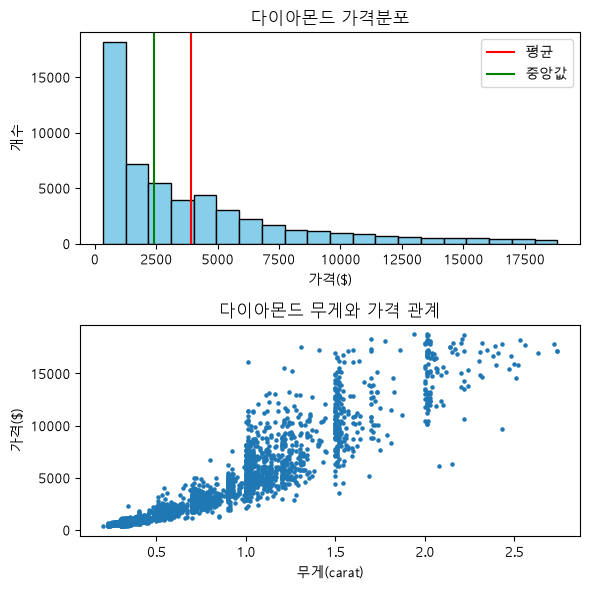

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(6,6))

# price 히스토그램
axes[0].hist(df["price"], bins=20, color="skyblue", edgecolor="black")

axes[0].set_title("다이아몬드 가격분포")
axes[0].set_xlabel("가격($)")
axes[0].set_ylabel("개수")

axes[0].axvline(clean["price"].mean(), color="red", label="평균")
axes[0].axvline(clean["price"].median(), color="green", label="중앙값")
axes[0].legend()

# carat과 price 산점도
clean_rnd = clean.sample(n=3000, random_state=random_state)
axes[1].scatter(clean_rnd["carat"], clean_rnd["price"], s=5)

axes[1].set_title("다이아몬드 무게와 가격 관계")
axes[1].set_xlabel("무게(carat)")
axes[1].set_ylabel("가격($)")

plt.tight_layout()
plt.show()

In [206]:
num_cols = clean.select_dtypes("number").columns.tolist() # ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
# df[num_cols] 

# price와 숫자 열들의 상관계수 출력(sort=desc)

# 1) corrwith 사용 방식
corr_with_price = (
    clean[num_cols]             # DataFrame
    .corrwith(clean["price"])   # Series
    .sort_values(ascending=False)
    )

# 2) corr 사용 방식
# corr_with_price = pd.Series({
#     col: (
#         clean["price"]          # Series
#         .corr(clean[col])       # float
#         ) for col in num_cols
# }).sort_values(ascending=False)

print(corr_with_price)

# 데이터프레임으로 출력해보기
corr_pd = pd.DataFrame({ "corr_with_price": corr_with_price })
corr_pd

# NOTE: carat 특성을 가격 예측에 사용한다.

price    1.000000
carat    0.921586
y        0.888818
x        0.887221
z        0.882107
table    0.127241
depth   -0.010653
dtype: float64


,corr_with_price
price,1.000000
carat,0.921586
y,0.888818
x,0.887221
z,0.882107
table,0.127241
depth,-0.010653


### M4 - 무게로 가격 예측
> **목표**: carat 하나로 선형 회귀를 학습해 w · b 의 뜻을 설명하고, 새 다이아몬드의 가격을 예측하고, 직선을 그림으로 확인한다.

> **생각해 볼 질문**
> 
> 0.25캐럿 다이아몬드의 예상가가 음수인 이유는 무엇일까요? 직선이 실제 점들보다 아래 · 위로 지나가는 구간은 각각 어디인가요? 평균 가격 가로선과 비교하면 직선은 무엇이 나아졌나요?

- 학습 결과 직선 기울기가 크게 나왔고, 그래서 y절편이 음수값이기 때문으로 보인다. 실제 데이터는 선형을 따르지 않기 때문에 이런 결과가 나온 것 같다.
- 처음에는 직선이 점들보다 아래에 위치해 있다가 0.3 ~ 0.5 캐럿 구간부터 위로 지나가고 있다.
- 평균가격 가로선보다는 직선이 훨씬 산점도를 잘 따른다. 무게에 따라 가격이 증가하는 경향을 잘 반영하고 있다.

In [207]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

X = clean[["carat"]]
y = clean["price"]

model.fit(X, y)
model

print(f"기울기 w = {model.coef_[0]:,.2f}") # 7,755.89
print(f"절편 b = {model.intercept_:,.2f}") # -2,255.86
# NOTE: 무게가 1캐럿 늘면 가격이 약 7756 달러 증가한다.

new = pd.DataFrame({"carat": [0.25, 0.5, 1.0, 2.0]})
model.predict(new).round(-1) # array([ -320.,  1620.,  5500., 13260.])
# NOTE: 0.25캐럿의 가격에 음수값 존재 ⚠️

기울기 w = 7,755.89
절편 b = -2,255.86


array([ -320.,  1620.,  5500., 13260.])

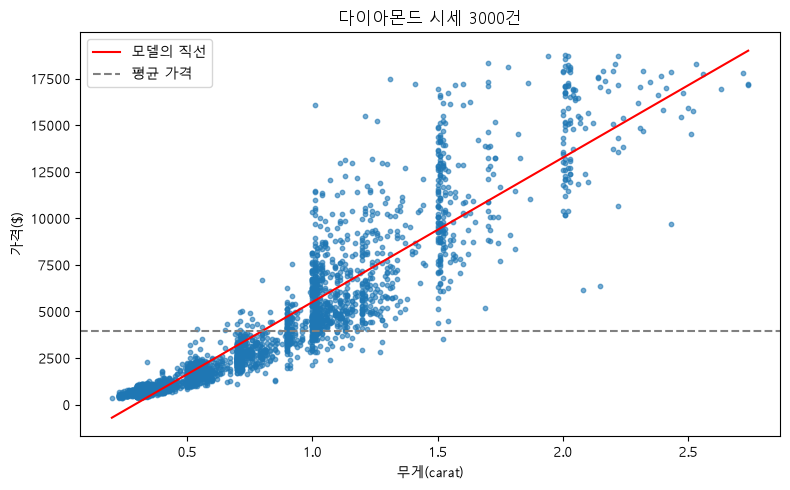

In [208]:
clean_rnd = clean.sample(n=3000, random_state=random_state)

# line = X.sort_values("carat")
line = clean_rnd[["carat"]].sort_values("carat")
line_pred = model.predict(line)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(clean_rnd["carat"], clean_rnd["price"], s=10, alpha=0.6)
ax.plot(line["carat"], line_pred, label="모델의 직선", color="red")
ax.axhline(clean["price"].mean(), label="평균 가격", color="gray", linestyle="--")

ax.set_title("다이아몬드 시세 3000건")
ax.set_xlabel("무게(carat)")
ax.set_ylabel("가격($)")
ax.legend()

plt.tight_layout()
plt.show()

### M5 - 특성 하나씩 직선 만들기
> **목표**: 숫자 6개 열 각각 하나로 직선을 만들어 그림으로 비교하고, 가격을 예측할 열을 고른 이유를 설명한다.

> **생각해 볼 질문**
> 
> 가격을 예측할 열로 carat 을 골랐다면 무엇을 근거로 삼았나요? z 의 w(약 5,085)가 table 의 w(약 227)보다 훨씬 큰데, z 가 table 보다 22배 좋은 열일까요? 열을 비교할 때는 w 대신 무엇을 보면 좋을까요?

- carat 열을 고른 이유는 상관계수가 1에 가까웠기 때문에 강한 양의 상관관계라고 보았기 때문이다.
- w값이 크다고 더 좋은 열은 아니다. 기울기는 변화량일뿐 x축에 영향을 받는다.
- 상관계수나 모델평가지표들(MAE, MSE, RMSE, R²)을 활용해야 한다.

['carat', 'depth', 'table', 'x', 'y', 'z']
{'carat': LinearRegression(), 'depth': LinearRegression(), 'table': LinearRegression(), 'x': LinearRegression(), 'y': LinearRegression(), 'z': LinearRegression()}
(2, 3)
(6,)


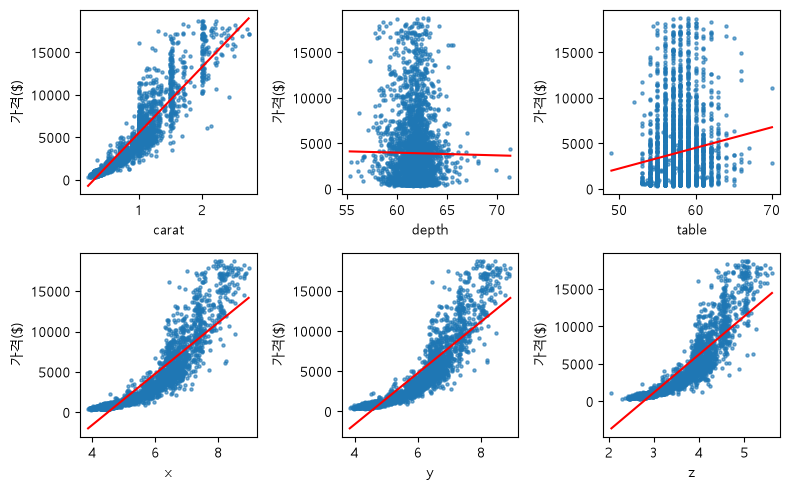

In [209]:
num_cols = (clean.select_dtypes("number") # DataFrame
            .columns                      # Pandas Index(['carat', 'depth', 'table', 'price', 'x', 'y', 'z'], dtype='str')
            .drop("price").tolist())
print(num_cols)                           # ['carat', 'depth', 'table', 'x', 'y', 'z']

models = {}
y = clean["price"]

for col in num_cols:
    model = LinearRegression()
    X = clean[[col]]
    model.fit(X, y)

    models[col] = model

print(models)


# 데이터 3,000개의 산점도 2행 3열
clean_rnd = clean.sample(n=3000, random_state=random_state)
fig, axes = plt.subplots(2, 3, figsize=(8, 5))

# ndarray.ravel(): NumPy에서 다차원 배열을 1차원 배열로 펼치는 메서드
print(axes.shape) # (2, 3)
print(axes.ravel().shape)  # (6,)

for ax, col in zip(axes.ravel(), num_cols):
    model = models[col]
    
    ax.scatter(clean_rnd[col], clean_rnd["price"], s=5, alpha=0.6)
    ax.set_xlabel(col)
    ax.set_ylabel("가격($)")

    line = clean_rnd[[col]].sort_values(col)
    line_pred = model.predict(line)
    ax.plot(line[col], line_pred, color="red")

plt.tight_layout()
plt.show()

# NOTE:
# 직선이 점들을 잘 따라가는 열: carat, x, y, z
# 직선이 점들을 못 따라가는 열: depth, table

In [ ]:
rows = [{
    "col": col,
    "w": models[col].coef_[0],
    "min": clean[col].min(),
    "max": clean[col].max()
    } for col in num_cols]

print(rows)

pd.DataFrame(rows).set_index("col")

[{'col': 'carat', 'w': np.float64(7755.886495228858), 'min': np.float64(0.2), 'max': np.float64(5.01)}, {'col': 'depth', 'w': np.float64(-29.654021234528262), 'min': np.float64(43.0), 'max': np.float64(79.0)}, {'col': 'table', 'w': np.float64(227.09172088144348), 'min': np.float64(43.0), 'max': np.float64(95.0)}, {'col': 'x', 'w': np.float64(3160.20674807972), 'min': np.float64(3.73), 'max': np.float64(10.74)}, {'col': 'y', 'w': np.float64(3189.0546700886352), 'min': np.float64(3.68), 'max': np.float64(10.54)}, {'col': 'z', 'w': np.float64(5085.376824971063), 'min': np.float64(1.07), 'max': np.float64(6.98)}]


,w,min,max
col,,,
carat,7755.886495,0.20,5.01
depth,-29.654021,43.00,79.00
table,227.091721,43.00,95.00
x,3160.206748,3.73,10.74
y,3189.054670,3.68,10.54
z,5085.376825,1.07,6.98
